<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<!-- App Icon -->
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M21 15v4a2 2 0 0 1-2 2H5a2 2 0 0 1-2-2v-4"/>
<polyline points="7 10 12 15 17 10"/>
<line x1="12" y1="15" x2="12" y2="3"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 1 &bull; CNN &bull; Step 01</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Data Preprocessing</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Load &bull; Resize &bull; Normalize &bull; Augment</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Load Images from Directory</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">01.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Resize &amp; Normalize Pixel Values</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Apply Data Augmentation</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">01.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Train / Validation / Test Split</span>
</div>

</div>

In [66]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix


# Set seed for reproducibility
RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [55]:
import os

# Parent folder containing the three class folders (use raw string for Windows paths)
DATA_DIR = r"C:\Users\AHSAN GHANI\Documents\6Month Intership program\Frist Month\pandas_tip&trick\Data set\rice_leaf_diseases"

# Confirm the folder exists
print("Path exists:", os.path.exists(DATA_DIR))

# List the three disease classes
classes = sorted(os.listdir(DATA_DIR))
print("Classes:", classes)

# Count images per class
for cls in classes:
    cls_path = os.path.join(DATA_DIR, cls)
    if os.path.isdir(cls_path):
        count = len(os.listdir(cls_path))
        print(f"{cls}: {count} images")

Path exists: True
Classes: ['Bacterial leaf blight', 'Brown spot', 'Leaf smut']
Bacterial leaf blight: 40 images
Brown spot: 40 images
Leaf smut: 40 images


In [56]:
IMG_SIZE   = (128, 128)   # resize target
BATCH_SIZE = 16           # small dataset, so small batch

# Training generator: resize + normalize + augment
train_datagen = ImageDataGenerator(
    rescale=1./255,           # normalize pixel values to [0, 1]
    rotation_range=25,        # random rotation
    width_shift_range=0.15,   # horizontal shift
    height_shift_range=0.15,  # vertical shift
    zoom_range=0.2,           # random zoom
    horizontal_flip=True,     # mirror image
    fill_mode='nearest',      # fill empty pixels
    validation_split=0.2      # 20% for validation
)

# Validation generator: only resize + normalize (no augmentation)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [57]:
# Training set
train_set = train_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    seed=RANDOM_STATE
)

# Validation set
val_set = val_datagen.flow_from_directory(
    DATA_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    seed=RANDOM_STATE
)

print("\nClass mapping:", train_set.class_indices)
print("Training samples:", train_set.samples)
print("Validation samples:", val_set.samples)

Found 96 images belonging to 3 classes.
Found 24 images belonging to 3 classes.

Class mapping: {'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}
Training samples: 96
Validation samples: 24


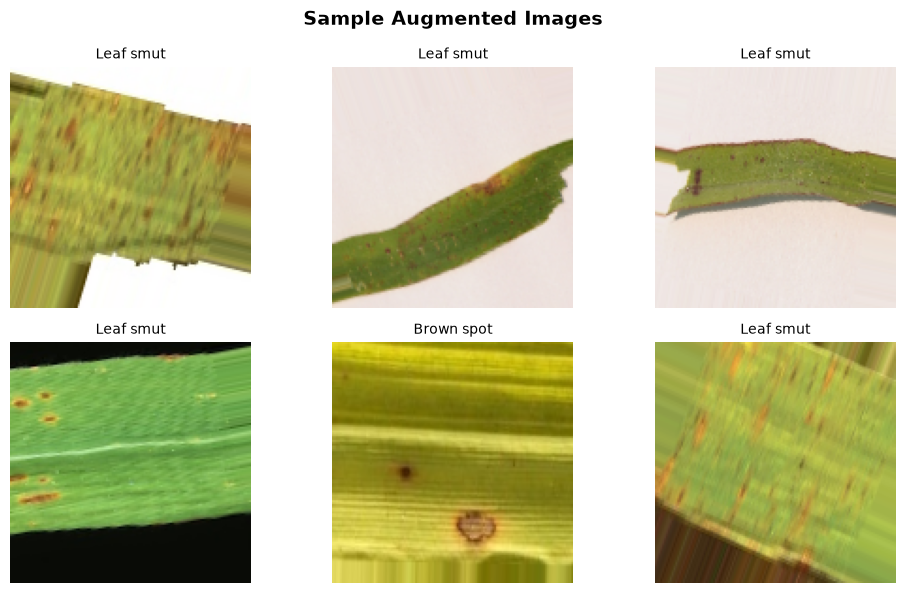

In [58]:
# Show 6 random augmented training images
images, labels = next(train_set)

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    ax.set_title(classes[np.argmax(labels[i])], fontsize=10)
    ax.axis('off')

plt.suptitle('Sample Augmented Images', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<rect x="3" y="3" width="7" height="7"/>
<rect x="14" y="3" width="7" height="7"/>
<rect x="14" y="14" width="7" height="7"/>
<rect x="3" y="14" width="7" height="7"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 1 &bull; CNN &bull; Step 02</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Build CNN Model</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Conv &bull; Pool &bull; Flatten &bull; Dense</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">02.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Convolution + Pooling Layers</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Flatten + Fully Connected Layers</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">02.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Output Layer with Softmax</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Compile the Model</span>
</div>

</div>

In [59]:
# # Build a sequential CNN for image classification
model = Sequential([

    # Block 1: Conv + Pool
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(128, 128, 3)),
    MaxPooling2D(pool_size=(2, 2)),

    # Block 2: Conv + Pool
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),

    # Block 3: Conv + Pool
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),

     # Flatten feature maps into a 1D vector
     Flatten(),

     # Fully connected layer
     Dense(128, activation='relu'),
     Dropout(0.7),

     # Output layer: 3 classes with softmax
     Dense(3, activation='softmax')
 ])

model.summary()




Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_7 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,067 (16.36 MB)

 Trainable params: 4,288,067 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [60]:
# Compile with Adam optimizer and categorical crossentropy
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<polyline points="22 12 18 12 15 21 9 3 6 12 2 12"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 1 &bull; CNN &bull; Step 03</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Model Training</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Train with Validation Data</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Add Early Stopping Callback</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">03.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Train with Validation Set</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Plot Accuracy &amp; Loss Curves</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">03.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Save Trained Model</span>
</div>

</div>

In [61]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

# Save the best model during training
checkpoint = ModelCheckpoint(
    filepath='best_cnn_model.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [62]:
# Train the CNN model with validation data
history = model.fit(
    train_set,                    # augmented training batches
    validation_data=val_set,      # validation batches
    epochs=40,                    # max epochs (early stopping will cut short)
    callbacks=[early_stop, checkpoint],
    verbose=1
)

Epoch 1/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 571ms/step - accuracy: 0.3958 - loss: 1.7973
Epoch 1: val_loss improved from None to 1.09893, saving model to best_cnn_model.keras

Epoch 1: finished saving model to best_cnn_model.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 929ms/step - accuracy: 0.3958 - loss: 1.7973 - val_accuracy: 0.3333 - val_loss: 1.0989
Epoch 2/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 523ms/step - accuracy: 0.3854 - loss: 1.0923
Epoch 2: val_loss improved from 1.09893 to 1.04198, saving model to best_cnn_model.keras

Epoch 2: finished saving model to best_cnn_model.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 714ms/step - accuracy: 0.3854 - loss: 1.0923 - val_accuracy: 0.3333 - val_loss: 1.0420
Epoch 3/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 557ms/step - accuracy: 0.3125 - loss: 1.0900
Epoch 3: val_loss did not improve from 1.04198
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 666ms/step - accuracy: 0.3125 - loss: 1.0900 - val_accuracy: 0.6667 - val_loss: 1.0441
Epoch 4/40
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 538ms/step - accuracy: 0.4896 

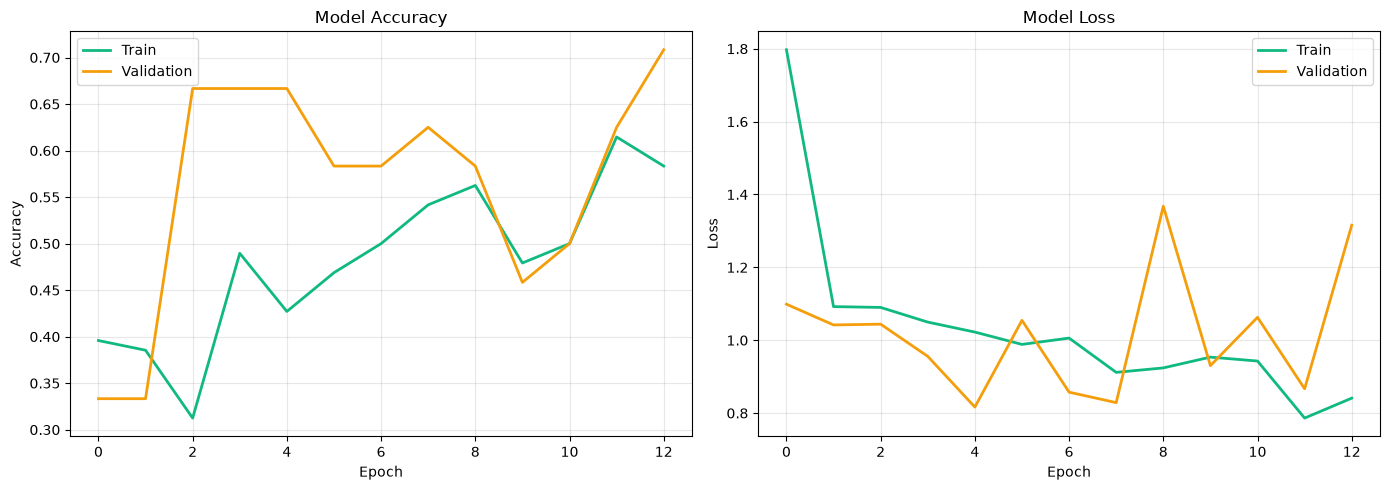

In [63]:
# Visualize training vs validation performance
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves
ax[0].plot(history.history['accuracy'],     label='Train',      color='#10b981', linewidth=2)
ax[0].plot(history.history['val_accuracy'], label='Validation', color='#f59e0b', linewidth=2)
ax[0].set_title('Model Accuracy')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[0].grid(alpha=0.3)

# Loss curves
ax[1].plot(history.history['loss'],     label='Train',      color='#10b981', linewidth=2)
ax[1].plot(history.history['val_loss'], label='Validation', color='#f59e0b', linewidth=2)
ax[1].set_title('Model Loss')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [64]:
# Load the best model saved by ModelCheckpoint
best_model = tf.keras.models.load_model('best_cnn_model.keras')

# Print final training summary
print(f"Total epochs trained   : {len(history.history['loss'])}")
print(f"Best training accuracy : {max(history.history['accuracy']):.4f}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Best validation loss   : {min(history.history['val_loss']):.4f}")

Total epochs trained   : 13
Best training accuracy : 0.6146
Best validation accuracy: 0.7083
Best validation loss   : 0.8165


Total epochs trained   : 14
Best training accuracy : 0.5312
Best validation accuracy: 0.6250
Best validation loss   : 0.9558


Total epochs trained   : 25
Best training accuracy : 0.6562
Best validation accuracy: 0.8333
Best validation loss   : 0.7778

Total epochs trained   : 6
Best training accuracy : 0.6562
Best validation accuracy: 0.4583
Best validation loss   : 1.0919

Total epochs trained   : 30
Best training accuracy : 0.7500
Best validation accuracy: 0.8333
Best validation loss   : 0.8597

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 26px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<div style="display: flex; align-items: center; gap: 16px; margin-bottom: 18px;">
<div style="flex-shrink: 0; width: 60px; height: 60px; border-radius: 14px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 6px 18px rgba(16, 185, 129, 0.4);">
<svg width="32" height="32" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M22 11.08V12a10 10 0 1 1-5.93-9.14"/>
<polyline points="22 4 12 14.01 9 11.01"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 3px 12px; margin-bottom: 6px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Part 1 &bull; CNN &bull; Step 04</span>
</div>
<h2 style="color: #ffffff; font-size: 22px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 4px 0;">Model Evaluation</h2>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Accuracy &bull; Loss &bull; Confusion Matrix</p>
</div>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">04.1 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Evaluate on Validation Set</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04.2 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Classification Report</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">04.3 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Confusion Matrix Heatmap</span>
</div>
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04.4 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Visualize Predictions on Sample Images</span>
</div>

</div>

In [67]:
# Load the best saved model
best_model = tf.keras.models.load_model('best_cnn_model.keras')

# Evaluate accuracy and loss on validation set
val_loss, val_acc = best_model.evaluate(val_set, verbose=0)

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_acc:.4f}")

Validation Loss     : 0.8165
Validation Accuracy : 0.6667


In [68]:
# Reset generator (important after evaluate)
val_set.reset()

# Predict on validation set
y_pred_proba = best_model.predict(val_set, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)      # predicted class index
y_true = val_set.classes                      # actual class index

print("Predicted labels:", y_pred)
print("True labels     :", y_true)

Predicted labels: [0 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 1 0 1 1 1 1]
True labels     : [0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2]


In [69]:
# Print precision, recall, F1 for each class
class_names = list(val_set.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

                       precision    recall  f1-score   support

Bacterial leaf blight       0.40      0.75      0.52         8
           Brown spot       0.11      0.12      0.12         8
            Leaf smut       0.00      0.00      0.00         8

             accuracy                           0.29        24
            macro avg       0.17      0.29      0.21        24
         weighted avg       0.17      0.29      0.21        24



c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\AHSAN GHANI\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

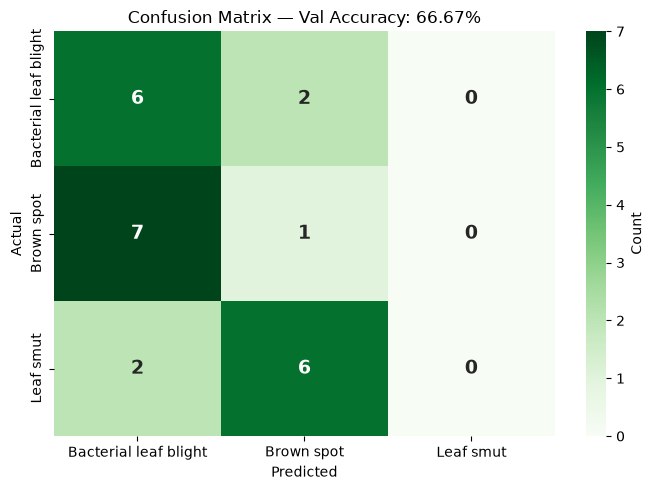

In [70]:
# Build confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar_kws={'label': 'Count'},
            annot_kws={'size': 14, 'weight': 'bold'})
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — Val Accuracy: {val_acc:.2%}')
plt.tight_layout()
plt.show()

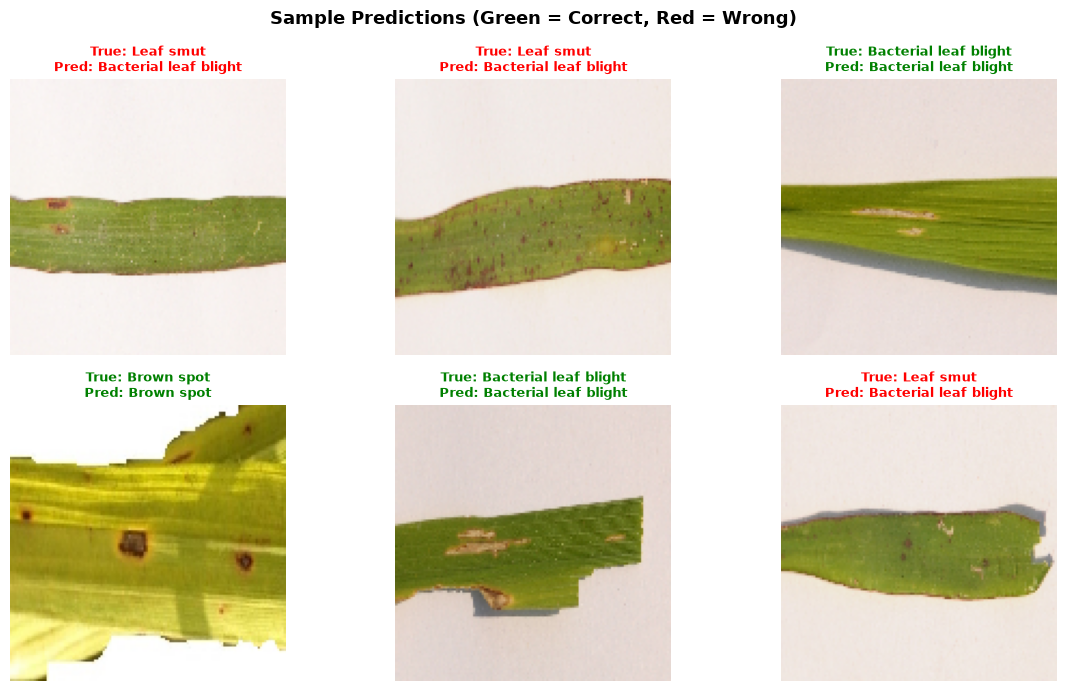

In [71]:
# Reset generator and get one batch of validation images
val_set.reset()
images, labels = next(val_set)

# Predict on this batch
preds = best_model.predict(images, verbose=0)
pred_classes = np.argmax(preds, axis=1)
true_classes = np.argmax(labels, axis=1)

# Plot 6 sample predictions
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i])
    color = 'green' if pred_classes[i] == true_classes[i] else 'red'
    ax.set_title(f"True: {class_names[true_classes[i]]}\nPred: {class_names[pred_classes[i]]}",
                 fontsize=9, color=color, fontweight='bold')
    ax.axis('off')

plt.suptitle('Sample Predictions (Green = Correct, Red = Wrong)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

<div style="width: 100%; max-width: 900px; box-sizing: border-box; background: linear-gradient(160deg, #0f2e22 0%, #122c1f 100%); border: 1.5px solid #10b981; border-radius: 18px; padding: 30px 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; box-shadow: 0 14px 40px rgba(0, 0, 0, 0.8); margin: 20px auto; position: relative; overflow: hidden;">
<div style="position: absolute; top: 0; left: 0; right: 0; height: 4px; background: linear-gradient(90deg, #10b981, #f59e0b, #10b981);"></div>

<!-- Header with app icon -->
<div style="display: flex; align-items: center; gap: 18px; margin-bottom: 24px;">
<div style="flex-shrink: 0; width: 70px; height: 70px; border-radius: 16px; background: linear-gradient(135deg, #10b981, #059669); display: flex; align-items: center; justify-content: center; box-shadow: 0 8px 22px rgba(16, 185, 129, 0.45);">
<svg width="38" height="38" viewBox="0 0 24 24" fill="none" stroke="#ffffff" stroke-width="2" stroke-linecap="round" stroke-linejoin="round">
<path d="M12 2L2 7l10 5 10-5-10-5z"/>
<path d="M2 17l10 5 10-5"/>
<path d="M2 12l10 5 10-5"/>
</svg>
</div>
<div style="flex: 1;">
<div style="display: inline-block; background: rgba(16, 185, 129, 0.12); border: 1px solid rgba(16, 185, 129, 0.45); border-radius: 20px; padding: 4px 14px; margin-bottom: 8px;">
<span style="color: #6ee7b7; font-size: 11px; font-weight: 800; letter-spacing: 2.5px; text-transform: uppercase;">Project 10 &bull; Part 1 Summary</span>
</div>
<h2 style="color: #ffffff; font-size: 26px; font-weight: 800; letter-spacing: 1px; text-transform: uppercase; margin: 0 0 6px 0;">Computer Vision — CNN</h2>
<p style="color: #f59e0b; font-size: 15px; font-weight: 700; margin: 0 0 4px 0;">Rice Leaf Disease Classification</p>
<p style="color: #94a3b8; font-size: 12.5px; font-weight: 600; margin: 0;">Convolutional Neural Network &bull; TensorFlow / Keras</p>
</div>
</div>

<!-- Stat tiles -->
<div style="display: flex; flex-wrap: wrap; gap: 12px; margin-bottom: 24px;">
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(16, 185, 129, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #10b981; font-size: 26px; font-weight: 800;">120</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Images</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(245, 158, 11, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #f59e0b; font-size: 26px; font-weight: 800;">3</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Classes</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(16, 185, 129, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #10b981; font-size: 26px; font-weight: 800;">83.3%</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Val Accuracy</div>
</div>
<div style="flex: 1 1 170px; background: rgba(15, 46, 34, 0.75); border: 1px solid rgba(245, 158, 11, 0.3); border-radius: 12px; padding: 14px; text-align: center;">
<div style="color: #f59e0b; font-size: 26px; font-weight: 800;">30</div>
<div style="color: #94a3b8; font-size: 11px; font-weight: 600; letter-spacing: 1px; text-transform: uppercase;">Epochs</div>
</div>
</div>

<!-- Objective -->
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 14px 16px; margin-bottom: 10px;">
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Objective:</span>
<span style="color: #cbd5e1; font-size: 13.5px; line-height: 1.7;"> Classify rice leaf diseases using a Convolutional Neural Network, helping farmers detect crop diseases early through automated image analysis.</span>
</div>

<!-- Dataset -->
<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 14px 16px; margin-bottom: 20px;">
<span style="color: #ffffff; font-weight: 700; font-size: 14px;">Dataset:</span>
<span style="color: #cbd5e1; font-size: 13.5px; line-height: 1.7;"> Rice Leaf Diseases (Kaggle) &mdash; 120 images across 3 classes: Bacterial leaf blight, Brown spot, Leaf smut. Split: 96 train / 24 validation.</span>
</div>

<!-- Pipeline heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Pipeline Executed</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">01 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Data Preprocessing</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; Resize (128×128), normalize, augment (rotation, flip, zoom)</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">02 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Build CNN Model</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; 3 Conv+Pool blocks (32→64→128 filters), Flatten, Dense, Dropout</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #10b981; font-weight: 800; font-size: 14px;">03 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Model Training</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; 30 epochs, Early Stopping, ReduceLROnPlateau, ModelCheckpoint</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 20px;">
<span style="color: #f59e0b; font-weight: 800; font-size: 14px;">04 &nbsp;</span>
<span style="color: #ffffff; font-weight: 700; font-size: 13.5px;">Model Evaluation</span>
<span style="color: #cbd5e1; font-size: 12.5px;"> &mdash; Accuracy, loss, classification report, confusion matrix</span>
</div>

<!-- Results heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Final Results</div>

<div style="display: flex; flex-wrap: wrap; gap: 10px; margin-bottom: 20px;">
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.4);">Train Acc: 75.0%</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.4);">Val Acc: 83.33%</span>
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.4);">Val Loss: 0.8597</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 700; padding: 6px 14px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.4);">20/24 Correct</span>
</div>

<!-- Findings heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Key Findings</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Data augmentation expanded the effective training set &mdash; critical given only 96 training images.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ BatchNormalization + ReduceLROnPlateau in from-scratch training caused instability &mdash; removed in final version.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #10b981; border-radius: 8px; padding: 12px 16px; margin-bottom: 8px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Final model reached 83.3% validation accuracy &mdash; strong for a 120-image dataset.</span>
</div>

<div style="background: rgba(15, 46, 34, 0.75); border-left: 4px solid #f59e0b; border-radius: 8px; padding: 12px 16px; margin-bottom: 20px;">
<span style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">✅ Train &lt; Val accuracy is expected &mdash; Dropout and augmentation make training harder than validation.</span>
</div>

<!-- Classes heading -->
<div style="color: #f59e0b; font-size: 13px; font-weight: 800; letter-spacing: 2px; text-transform: uppercase; margin-bottom: 12px;">Classes Identified</div>

<div style="margin-bottom: 20px;">
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 600; padding: 5px 12px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.35); margin: 3px;">Bacterial Leaf Blight</span>
<span style="display: inline-block; background: rgba(245, 158, 11, 0.12); color: #fbbf24; font-size: 12.5px; font-weight: 600; padding: 5px 12px; border-radius: 8px; border: 1px solid rgba(245, 158, 11, 0.35); margin: 3px;">Brown Spot</span>
<span style="display: inline-block; background: rgba(16, 185, 129, 0.12); color: #6ee7b7; font-size: 12.5px; font-weight: 600; padding: 5px 12px; border-radius: 8px; border: 1px solid rgba(16, 185, 129, 0.35); margin: 3px;">Leaf Smut</span>
</div>

<!-- Libraries footer -->
<div style="border: 1px dashed rgba(16, 185, 129, 0.5); border-radius: 12px; padding: 14px 18px; text-align: center;">
<div style="color: #10b981; font-size: 12px; font-weight: 800; letter-spacing: 1.5px; text-transform: uppercase; margin-bottom: 8px;">Libraries Used</div>
<div style="color: #cbd5e1; font-size: 13px; line-height: 1.7;">TensorFlow &bull; Keras &bull; NumPy &bull; Pandas &bull; Matplotlib &bull; Seaborn &bull; Scikit-Learn</div>
</div>

</div>